# Crop Disease Detection Using PlantVillage

## 1. Introduction

In this project, I used leaf images from the PlantVillage dataset to classify crop leaves into 38 different classes, including healthy leaves and leaves affected by different diseases.

I also prepared prediction and retraining functions that can be used later in the application.

## 2. Import Libraries

I imported the libraries needed for loading, processing, visualizing and training the model.

In [ ]:
!pip install importlib_resources

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


## 3. Data Acquisition

I loaded the PlantVillage dataset using TensorFlow Datasets. It contains 54,303 leaf images in 38 classes of healthy and unhealthy crop leaves.

Dataset source: https://www.tensorflow.org/datasets/catalog/plant_village

In [ ]:
dataset_name = "plant_village"

(train_raw, validation_raw, test_raw), dataset_info = tfds.load(
    dataset_name,
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True,
    with_info=True
)

class_names = dataset_info.features["label"].names
number_of_classes = len(class_names)

print("Number of images:", dataset_info.splits["train"].num_examples)
print("Number of classes:", number_of_classes)
print("Class names:")
for name in class_names:
    print(name)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.PPQHJ8_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Number of images: 54303
Number of classes: 38
Class names:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry___healthy
Cherry___Powdery_mildew
Corn___Cercospora_leaf_spot Gray_leaf_spot
Corn___Common_rust
Corn___healthy
Corn___Northern_Leaf_Blight
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___healthy
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___healthy
Potato___Late_blight
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___healthy
Strawberry___Leaf_scorch
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___healthy
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Tw

## 4. Dataset Exploration

I checked the number of images in each split and viewed some sample images.

In [ ]:
image_size = (128, 128)
batch_size = 32
AUTOTUNE = tf.data.AUTOTUNE

train_count = dataset_info.splits["train"].num_examples
train_size = int(train_count * 0.80)
validation_size = int(train_count * 0.10)
test_size = train_count - train_size - validation_size

print("Training images:", train_size)
print("Validation images:", validation_size)
print("Testing images:", test_size)

Training images: 43442
Validation images: 5430
Testing images: 5431


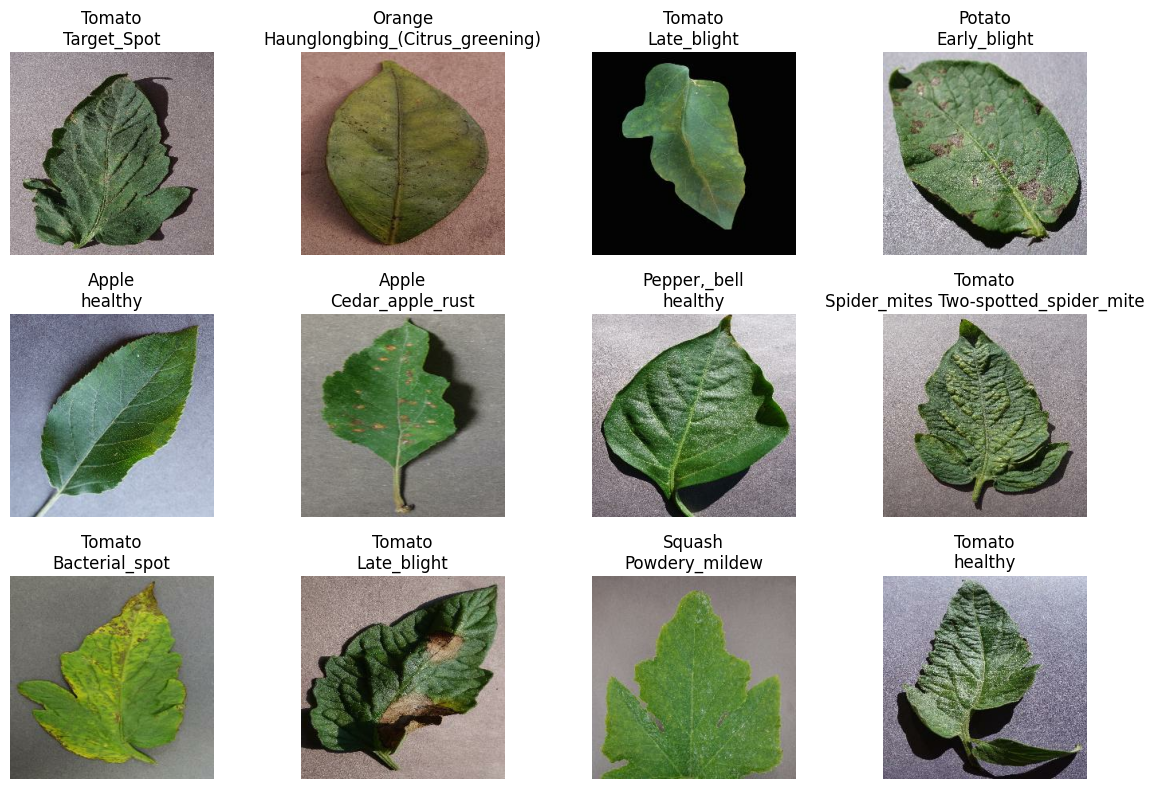

In [ ]:
class_names = dataset_info.features["label"].names
train_batch = train_raw.batch(batch_size)

# Display images
plt.figure(figsize=(12, 8))

for images, labels in train_batch.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[int(labels[i])].replace("___", "\n"))
        plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Data Visualizations

I checked the class distribution and looked at some visible features in the leaf images.

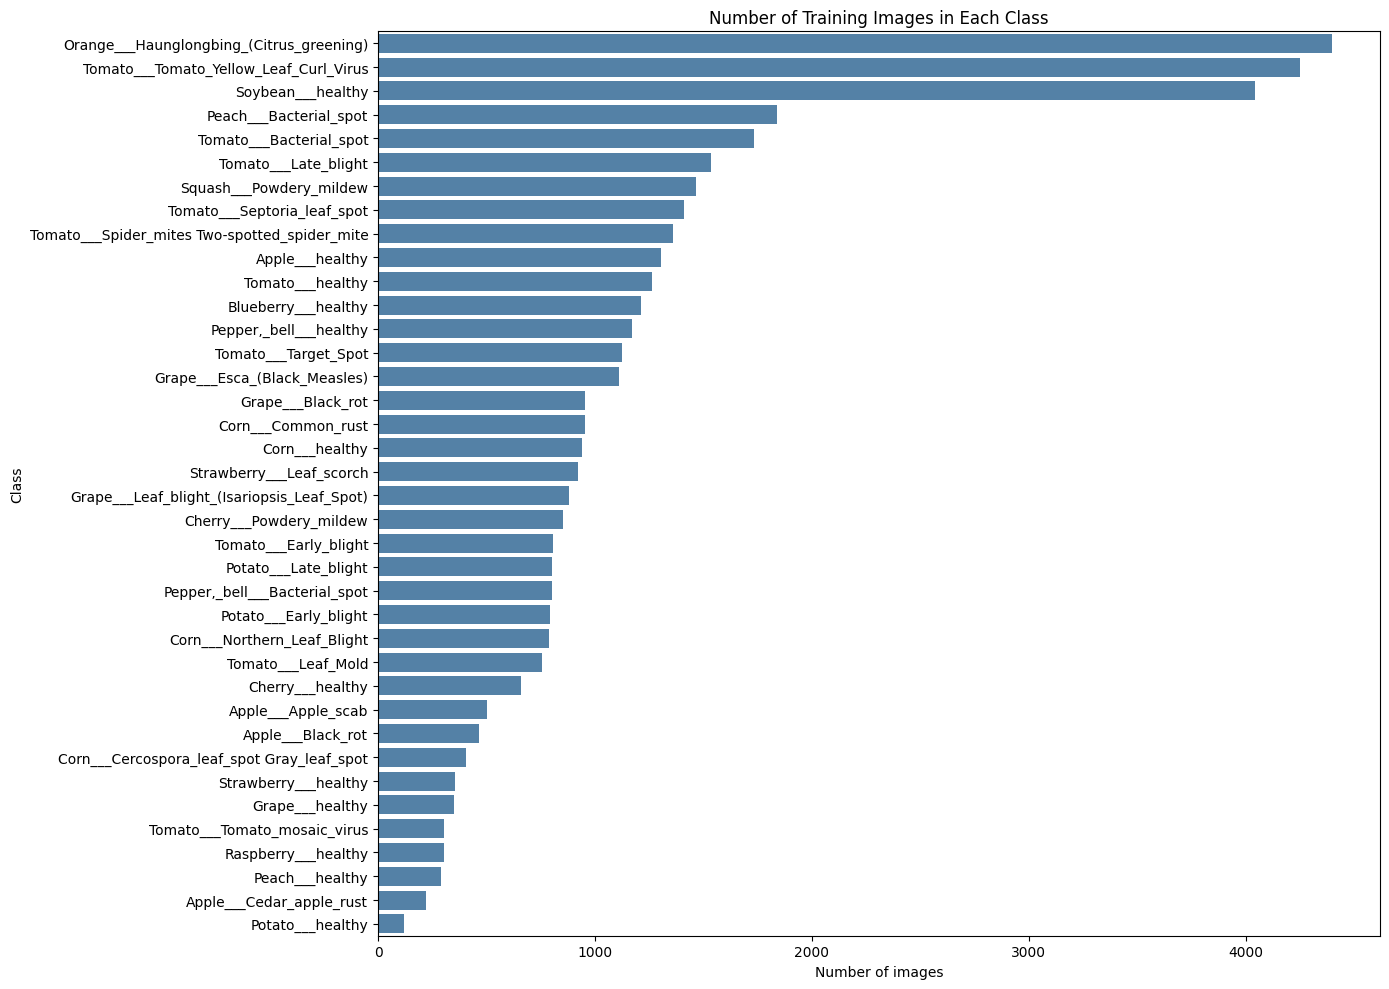

,Class,Number of images
15,Orange___Haunglongbing_(Citrus_greening),4399
37,Tomato___Tomato_Yellow_Leaf_Curl_Virus,4252
24,Soybean___healthy,4043
16,Peach___Bacterial_spot,1838
28,Tomato___Bacterial_spot,1732
31,Tomato___Late_blight,1535
25,Squash___Powdery_mildew,1466
33,Tomato___Septoria_leaf_spot,1409
34,Tomato___Spider_mites Two-spotted_spider_mite,1360
3,Apple___healthy,1306


In [ ]:
# Count the images in each class
class_counts = np.zeros(number_of_classes, dtype=int)

for _, labels in train_raw:
    class_counts[int(labels.numpy())] += 1

class_distribution = pd.DataFrame({
    "Class": class_names,
    "Number of images": class_counts
}).sort_values("Number of images", ascending=False)

plt.figure(figsize=(14, 10))
sns.barplot(data=class_distribution, x="Number of images", y="Class", color="steelblue")
plt.title("Number of Training Images in Each Class")
plt.tight_layout()
plt.show()

display(class_distribution)

### What I observed

I looked at three visible image features:

1. **Leaf colour:** Healthy leaves often have a more consistent green colour, while some diseased leaves show yellowing or brown areas.
2. **Spots and lesions:** Some diseases show visible spots, patches or damaged areas on the leaf.
3. **Leaf texture and shape:** Different diseases can affect the surface and edges of leaves. These differences may help the model separate the classes.

These are visual observations from the images. The model learns patterns from the full images rather than using these features as separate columns.

## 6. Image Preprocessing

I resized the images to 128 × 128 pixels and normalized their pixel values. I also prepared the datasets in batches.

In [ ]:
def prepare_image(image, label):
    image = tf.image.resize(image, image_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_data = (
    train_raw
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .shuffle(1000)
    .batch(batch_size)
    .prefetch(AUTOTUNE)
)

validation_data = (
    validation_raw
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(batch_size)
    .prefetch(AUTOTUNE)
)

test_data = (
    test_raw
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(batch_size)
    .prefetch(AUTOTUNE)
)

print("Image preprocessing completed.")

Image preprocessing completed.


## 7. Model Creation

I created a convolutional neural network (CNN) with image augmentation, convolutional layers, dropout and a softmax output layer for the 38 classes.

In [ ]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(number_of_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,292,582 (16.37 MB)

 Trainable params: 4,292,582 (16.37 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Model Training

I trained the model using the training images and checked its performance on the validation images. I used early stopping and learning rate reduction to help improve training.

In [10]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=15,
    callbacks=[early_stopping, reduce_learning_rate]
)

Epoch 1/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1938s 1s/step - accuracy: 0.4011 - loss: 2.1905 - val_accuracy: 0.6235 - val_loss: 1.2771 - learning_rate: 0.0010
Epoch 2/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1869s 1s/step - accuracy: 0.6012 - loss: 1.3382 - val_accuracy: 0.7641 - val_loss: 0.7773 - learning_rate: 0.0010
Epoch 3/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1857s 1s/step - accuracy: 0.6736 - loss: 1.0660 - val_accuracy: 0.8070 - val_loss: 0.6216 - learning_rate: 0.0010
Epoch 4/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1863s 1s/step - accuracy: 0.7132 - loss: 0.9220 - val_accuracy: 0.8116 - val_loss: 0.5954 - learning_rate: 0.0010
Epoch 5/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1859s 1s/step - accuracy: 0.7439 - loss: 0.8076 - val_accuracy: 0.8774 - val_loss: 0.3807 - learning_rate: 0.0010
Epoch 6/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1918s 1s/step - accuracy: 0.7695 - loss: 0.7221 - val_accuracy: 0.8838 - val_loss: 0.3628 - learning_rate: 0.0010
Epoch 7/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1890s 1s/step - accura

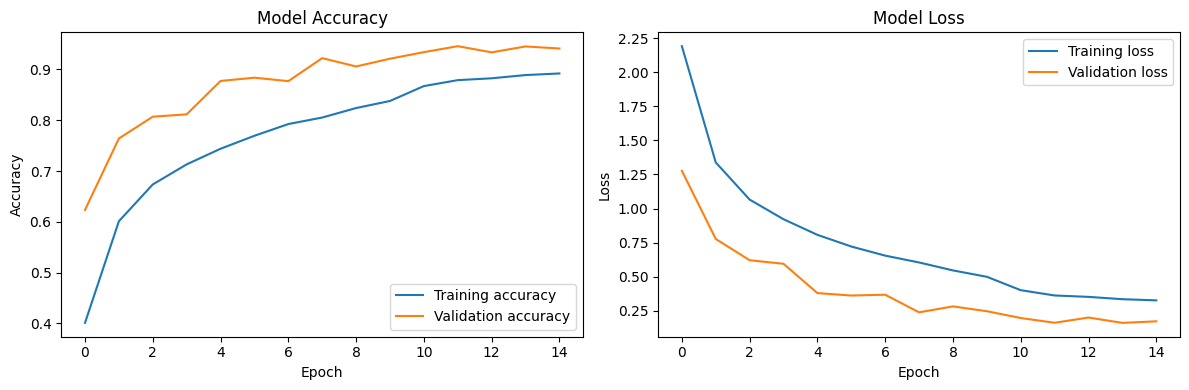

In [11]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Model Evaluation

I evaluated the trained model using the test images. I used accuracy, precision, recall, F1-score and loss.

In [12]:
test_loss, test_accuracy = model.evaluate(test_data, verbose=1)

y_true = np.concatenate([labels.numpy() for _, labels in test_data])
y_probabilities = model.predict(test_data, verbose=1)
y_pred = np.argmax(y_probabilities, axis=1)

test_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
test_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

results = pd.DataFrame({
    "Metric": ["Test loss", "Accuracy", "Macro precision", "Macro recall", "Macro F1-score"],
    "Value": [test_loss, test_accuracy, test_precision, test_recall, test_f1]
})

display(results)

170/170 ━━━━━━━━━━━━━━━━━━━━ 60s 355ms/step - accuracy: 0.9455 - loss: 0.1690
170/170 ━━━━━━━━━━━━━━━━━━━━ 59s 346ms/step


,Metric,Value
0,Test loss,0.169030
1,Accuracy,0.945488
2,Macro precision,0.936281
3,Macro recall,0.922976
4,Macro F1-score,0.926836


In [13]:
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(number_of_classes),
    target_names=class_names,
    zero_division=0
))

                                               precision    recall  f1-score   support

                           Apple___Apple_scab       0.83      0.86      0.85        58
                            Apple___Black_rot       0.94      0.98      0.96        65
                     Apple___Cedar_apple_rust       1.00      0.84      0.91        25
                              Apple___healthy       0.95      0.92      0.94       159
                          Blueberry___healthy       0.98      0.98      0.98       133
                             Cherry___healthy       1.00      0.98      0.99        90
                      Cherry___Powdery_mildew       1.00      0.97      0.98       100
   Corn___Cercospora_leaf_spot Gray_leaf_spot       0.65      0.84      0.73        56
                           Corn___Common_rust       0.99      0.98      0.99       127
                               Corn___healthy       1.00      1.00      1.00       112
                  Corn___Northern_Leaf_Bli

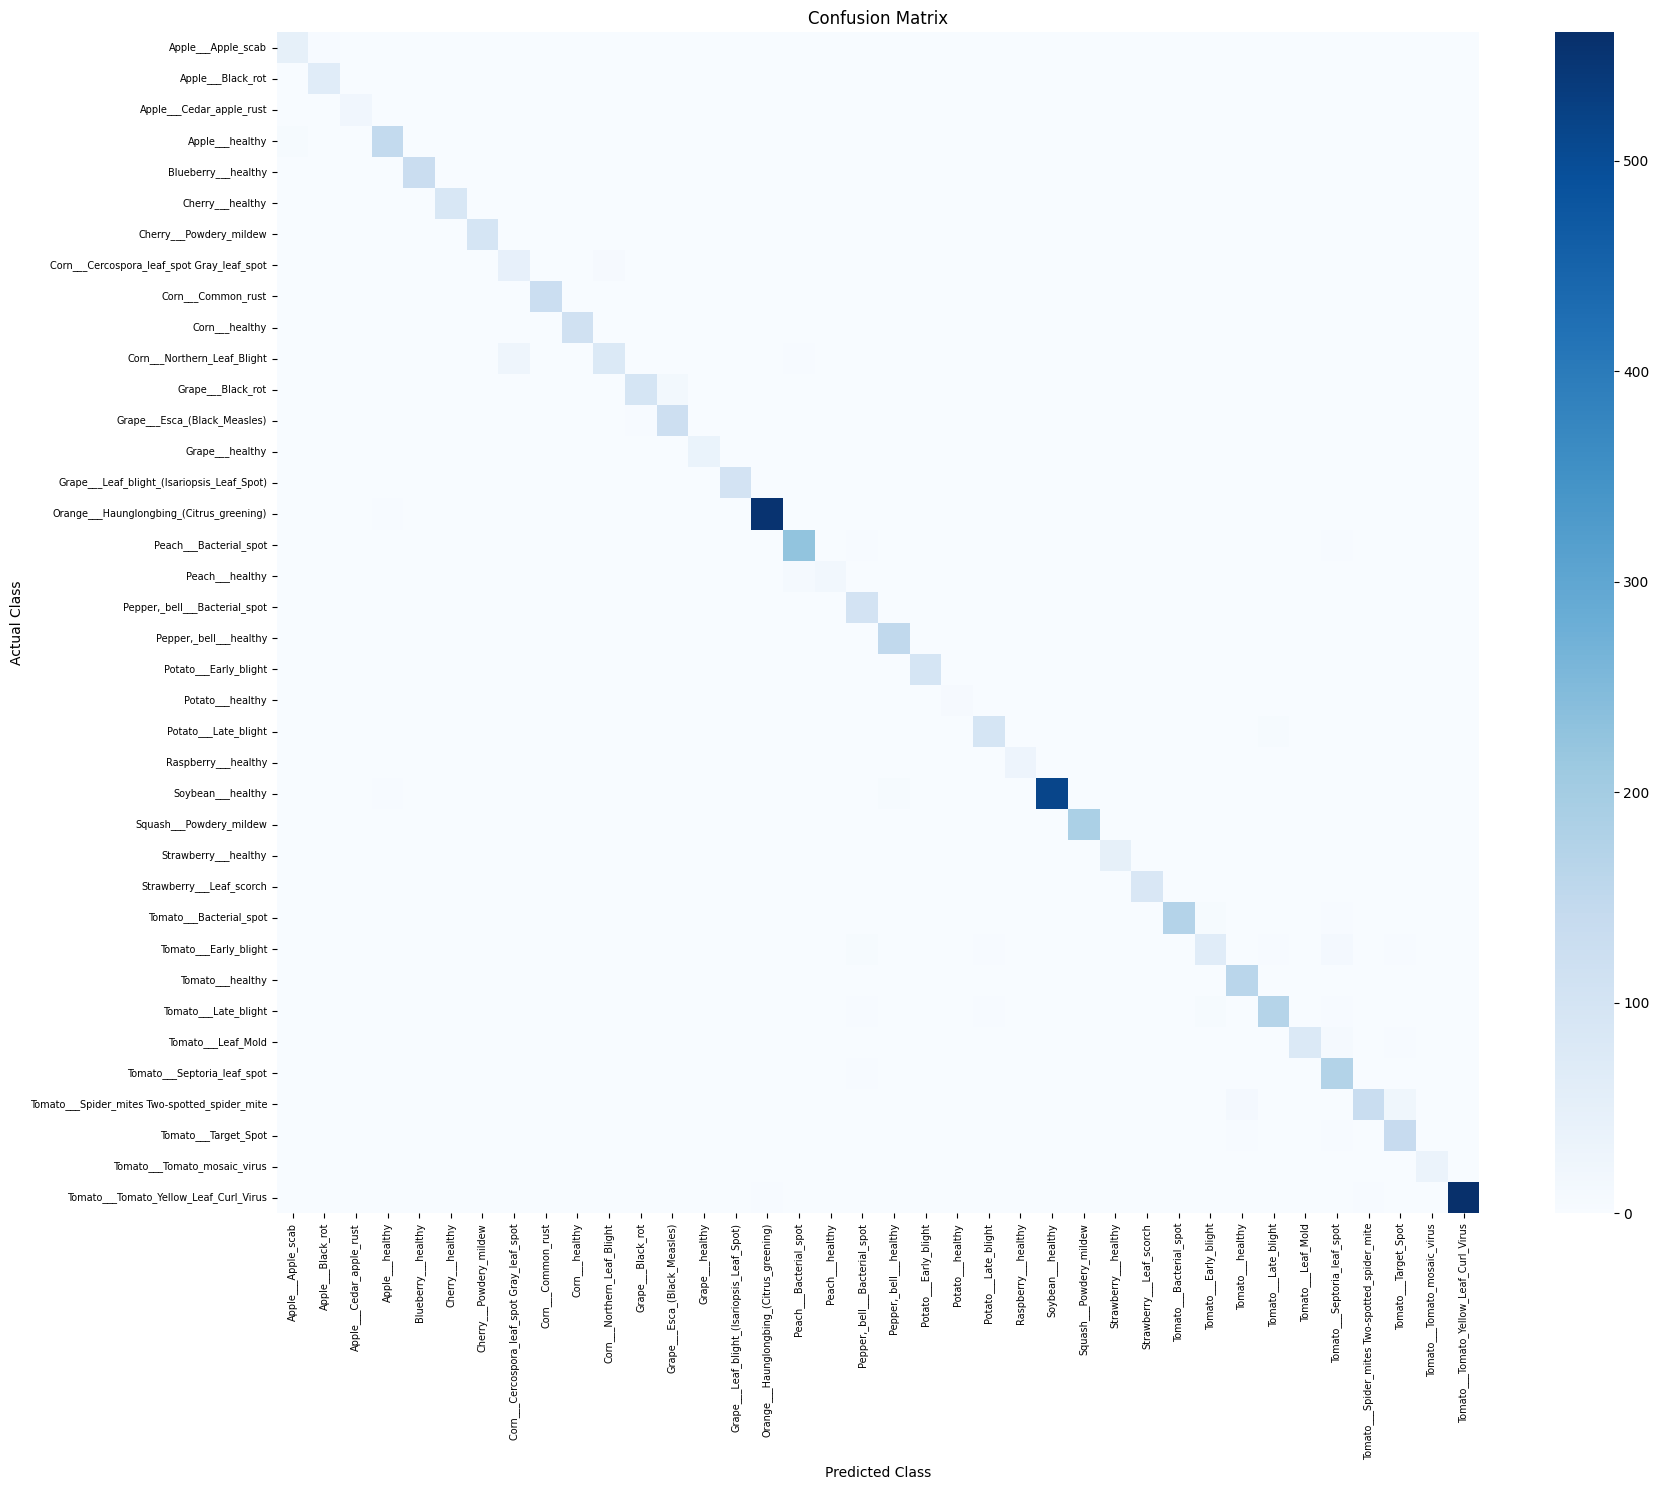

In [24]:
conf_matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(number_of_classes)
)

plt.figure(figsize=(18, 15))
sns.heatmap(
    conf_matrix,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

## 10. Prediction Function

I created a function that accepts one leaf image and returns the predicted class and confidence.

In [25]:
def predict_image(image_path):
    image = tf.keras.utils.load_img(image_path, target_size=image_size)
    image_array = tf.keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index])

    print("Predicted class:", predicted_class)
    print("Confidence:", round(confidence * 100, 2), "%")

    return predicted_class, confidence

In [26]:
# Replace with the name of your uploaded image
image_path = "sample_leaf.jpg"

# Predict the disease
predicted_class, confidence = predict_image(image_path)

Predicted class: Pepper,_bell___healthy
Confidence: 100.0 %


## 11. Save the Model

I saved the trained model so it can be loaded later by the prediction API and the application.

In [27]:
os.makedirs("models", exist_ok=True)

model.save("models/crop_disease_model.h5")

# Save the class names so the labels remain in the correct order
with open("models/class_names.txt", "w") as file:
    for class_name in class_names:
        file.write(class_name + "\n")

print("Model and class names saved.")

Model and class names saved.


## 12. New Data Upload and Retraining

I prepared a function for retraining the saved model with new labelled images. The uploaded images must be arranged in folders using the same 38 class names.

Folder example:

`new_data/Apple___Apple_scab/image1.jpg`

`new_data/Apple___healthy/image2.jpg`

The same class order is used to make sure the labels remain correct.

In [29]:
def retrain_model(new_data_folder, epochs=5):
    if not os.path.isdir(new_data_folder):
        raise FileNotFoundError("The new data folder was not found.")

    uploaded_classes = [
        name for name in class_names
        if os.path.isdir(os.path.join(new_data_folder, name))
    ]

    if not uploaded_classes:
        raise ValueError("No folders with valid class names were found.")

    unknown_classes = [
        name for name in os.listdir(new_data_folder)
        if os.path.isdir(os.path.join(new_data_folder, name))
        and name not in class_names
    ]

    if unknown_classes:
        raise ValueError("Unknown class folders: " + str(unknown_classes))

    new_data = tf.keras.utils.image_dataset_from_directory(
        new_data_folder,
        labels="inferred",
        label_mode="int",
        class_names=uploaded_classes,
        image_size=image_size,
        batch_size=batch_size,
        shuffle=True
    )

    # Changed the uploaded labels to match the original model class order
    original_labels = [class_names.index(name) for name in uploaded_classes]

    new_data = new_data.map(
        lambda image, label: (
            tf.cast(image, tf.float32) / 255.0,
            tf.gather(original_labels, label)
        ),
        num_parallel_calls=AUTOTUNE
    ).prefetch(AUTOTUNE)

    retraining_history = model.fit(
        new_data,
        epochs=epochs
    )

    model.save("models/crop_disease_model.h5")

    print("Retraining completed and the updated model was saved.")

    return retraining_history

### Retraining example

I left the function ready to use. When new labelled images are available, I can place them in the correct class folders and call the function below.

The application will later provide the upload button and the retraining trigger.

In [ ]:
# Retrain the model using a new folder of labelled images
# retraining_history = retrain_model("new_data", epochs=5)

## 13. Conclusion

I trained and evaluated a CNN model to classify crop leaf images using the PlantVillage dataset. I also prepared functions for predicting a single image and retraining the model with new labelled images.

The saved model will be used in the API and web application.